In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import scanpy as sc


import gcscan

In [2]:
st_data = sc.read_h5ad('example_data.h5ad')
coords = pd.read_parquet('example_data_geom.parquet')['coords']

import json
coords = coords = np.array([np.array(json.loads(c)) for c in coords], dtype = object)

cdf = st_data.obs

In [3]:
st_data.obs['label'].value_counts().sort_index()

label
B - non GC                    17124
B - GC                         3866
CCL19/21- Fibroblast           5829
Endothelial                    9343
Follicular Dendritic Cells     1409
CCL19/21+ Fibroblasts         10422
LAMP3+ DC                        73
Myeloids                       5382
Plasma Cells                   1105
TCF7+ CD4 T cells              7857
TCF7+ CD8 T cells             10173
TCF7- CD8 T cells              8280
Follicular Helper T cells      2059
undefined                      8973
Name: count, dtype: int64

In [4]:
# cell types that are expected to be in target structures
TLS_cell_types = [
    'B - GC',
    'B - non GC',
    'Follicular Dendritic Cells',
    'Follicular Helper T cells',
]

GC_cell_types = [
    'B - GC'
]


In [5]:
E_df, V_df, cut_df = gcscan.gcscan(
    xy = cdf[['x','y']].values,
    coords = coords,
    involved = cdf['label'].isin(TLS_cell_types).values, 
    # num_cpus = 8, # only relevent when using boundary-defined edges
    # boundary_dist_threshold = 5, 
    # boundary_dist_factor = -0.4,
    radius = 25, # max distance for edges
    minimal_neighbor_count = 3,
    watershed_min_weight = 0.4, 
    watershed_initial_threshold = 0.79,
    ncut_threshold = 0.005, 
    iscore = cdf['label'].isin(GC_cell_types).values, 
    verbose = True,
    edge_method = 'delaunay', # accurate enough in most cases
)

17:42:50    91895 cells, 545966 edges.
17:42:56    graph constructed. Running global clustering
17:42:56    117 clusters detected. Partitioning...
17:43:00    117 clusters partitioned.
17:43:01    26 final clusters.


In [6]:
GC_df = gcscan.calculate_GC_df(V_df, cdf)

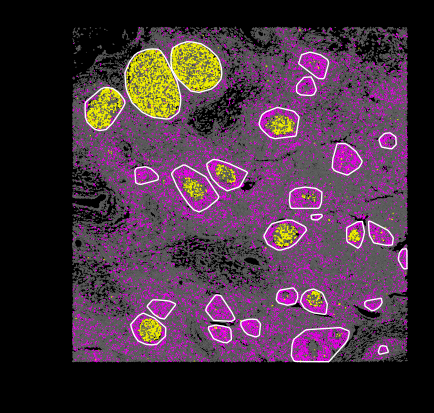

In [7]:
palette = {'B - GC': '#FFFF00',
           'B - non GC': '#FF00FF',}

color_other = '#666666'


from matplotlib import path as mpath
from matplotlib.collections import PathCollection


_, ax = plt.subplots(facecolor = 'k')

# draw cells
paths = [mpath.Path(c) for c in coords]
colors = [palette[c] if c in palette.keys() else color_other for c in cdf['label']]

collection = PathCollection(
        paths, 
        facecolors = colors, 
        edgecolors = colors, 
        linewidth = 0.2,
)

ax.add_collection(collection)

# draw structures
ax.add_collection(PathCollection(
        paths = [mpath.Path(c) for c in GC_df['coords']], 
        facecolors = 'none', 
        edgecolors = 'w', 
        linewidth = 1,
    ))

ax.set_facecolor('k')
ax.invert_yaxis()
ax.set_aspect('equal')
ax.autoscale_view()

In [8]:
st_data.obs['TLS_id'] = gcscan.assign_TLS_id(GC_df, cdf)
st_data.obs['TLS_id'] = st_data.obs['TLS_id'].astype('category')

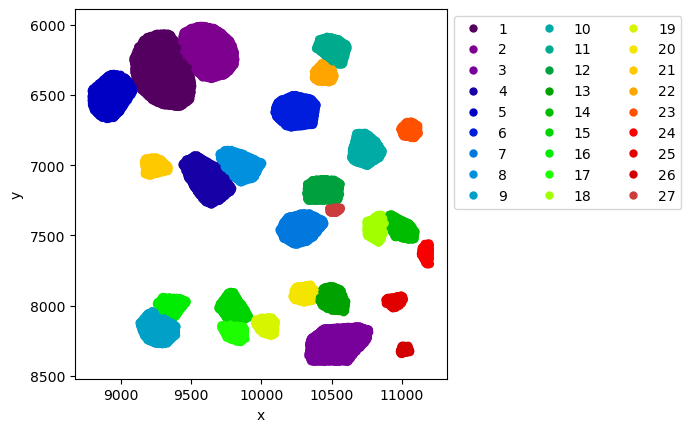

In [9]:
import seaborn as sns
ax = sns.scatterplot(data = st_data.obs,
               x = 'x',
               y = 'y',
               hue = 'TLS_id',
               edgecolor = 'none',
               palette = 'nipy_spectral'
               )

ax.invert_yaxis()
ax.set_aspect('equal')
ax.legend(bbox_to_anchor = [1,1], ncols = 3)
ax.autoscale_view()